# Exploratory Data Analysis: Compensation and Correlation

Part of my IBM Data Analyst Capstone project. In this notebook I look at how yearly compensation is distributed, compare it across countries, remove outliers, and measure how compensation relates to work experience and job satisfaction.

Only respondents who reported their compensation are included in the compensation analysis.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Load the data

In [1]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"
df = pd.read_csv(file_url)

df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


## 2. Distribution of yearly compensation
The histogram is stretched out by a small number of extremely high values, which is why outliers are removed later.

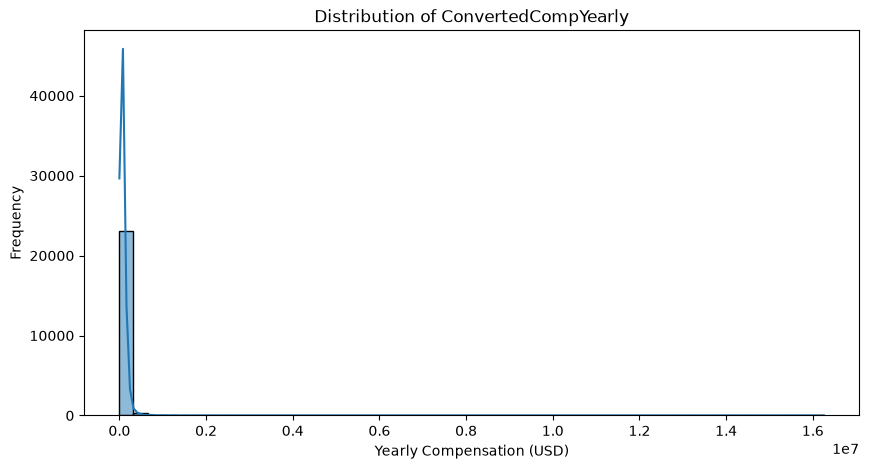

In [2]:
plt.figure(figsize=(10, 5))
sns.histplot(df['ConvertedCompYearly'].dropna(), bins=50, kde=True)
plt.title('Distribution of ConvertedCompYearly')
plt.xlabel('Yearly Compensation (USD)')
plt.ylabel('Frequency')
plt.show()

## 3. Median compensation of full-time employees

In [3]:
full_time = df[df['Employment'] == 'Employed, full-time']
median_comp = full_time['ConvertedCompYearly'].median()
print(f"Median compensation (Employed, full-time): {median_comp:,.2f}")

Median compensation (Employed, full-time): 69,814.00

## 4. Compensation by country
Box plots for the ten countries with the most respondents.

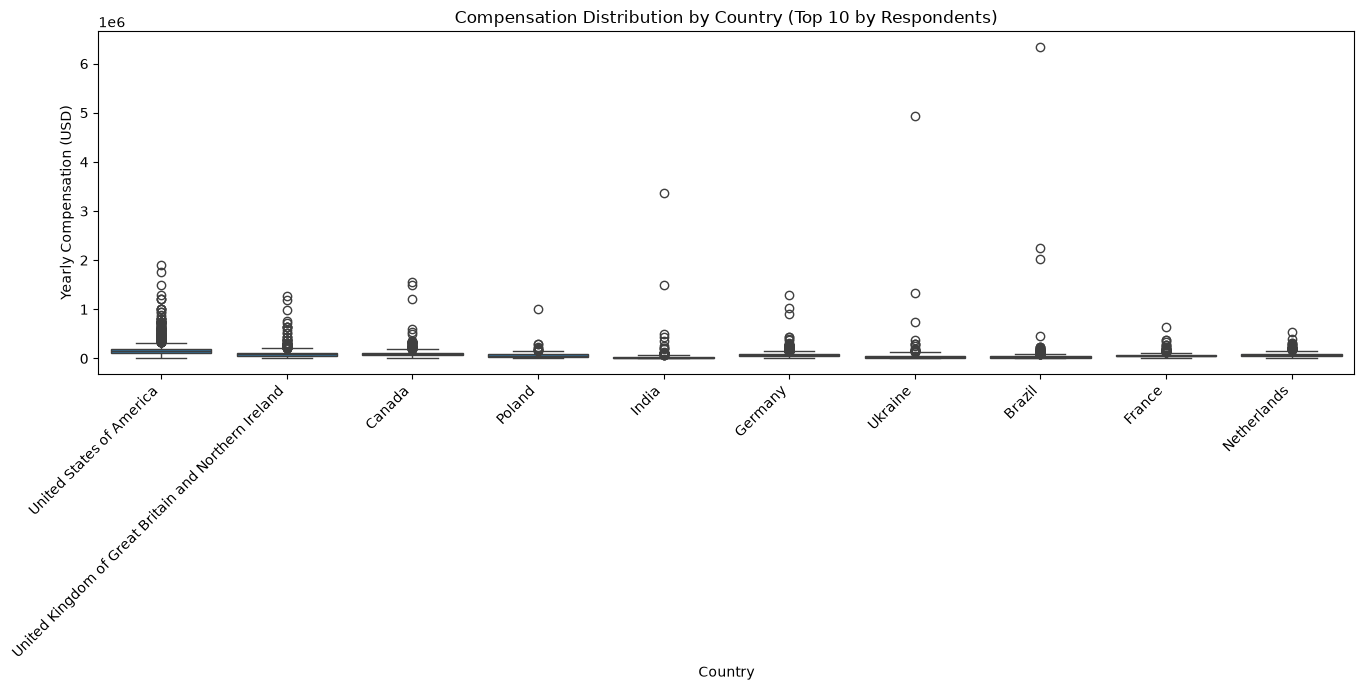

In [4]:
# Use the 10 countries with the most respondents so the plot stays readable
top_countries = df['Country'].value_counts().head(10).index
df_top = df[df['Country'].isin(top_countries)]

plt.figure(figsize=(14, 7))
sns.boxplot(x='Country', y='ConvertedCompYearly', data=df_top)
plt.title('Compensation Distribution by Country (Top 10 by Respondents)')
plt.xlabel('Country')
plt.ylabel('Yearly Compensation (USD)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Remove outliers
Outliers are values outside 1.5 x IQR from the quartiles, the same method as in the outlier notebook. Respondents who did not report pay are not outliers, so they are excluded first and counted separately.

In [ ]:
Q1 = df['ConvertedCompYearly'].quantile(0.25)
Q3 = df['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Bounds: {lower_bound:,.2f} to {upper_bound:,.2f}")

# Keep only respondents who reported pay, then remove the outliers among them
reported = df[df['ConvertedCompYearly'].notna()]
df_no_outliers = reported[(reported['ConvertedCompYearly'] >= lower_bound) &
                          (reported['ConvertedCompYearly'] <= upper_bound)].copy()

print("Rows with reported compensation:", len(reported))
print("Outliers removed:", len(reported) - len(df_no_outliers))
print("Rows in the new DataFrame:", len(df_no_outliers))

## 6. Correlation between compensation, experience and job satisfaction

                     ConvertedCompYearly   WorkExp  JobSatPoints_1
ConvertedCompYearly             1.000000  0.408438       -0.058170
WorkExp                         0.408438  1.000000       -0.032388
JobSatPoints_1                 -0.058170 -0.032388        1.000000

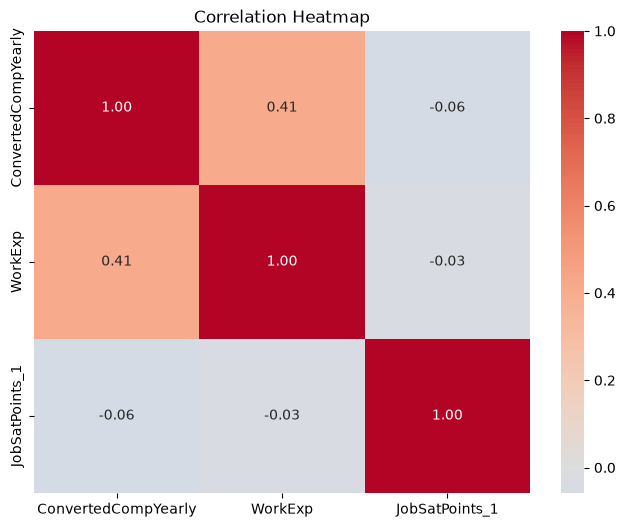

In [5]:
corr_cols = ['ConvertedCompYearly', 'WorkExp', 'JobSatPoints_1']
corr_matrix = df_no_outliers[corr_cols].corr()
print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

Compensation has a moderate positive correlation with work experience (about 0.41), and almost none with job satisfaction (about -0.06). Experience and job satisfaction are also barely related (about -0.03). Correlation does not show cause: it only says that people with more experience tend to report higher pay in this survey.

## 7. Scatter plots

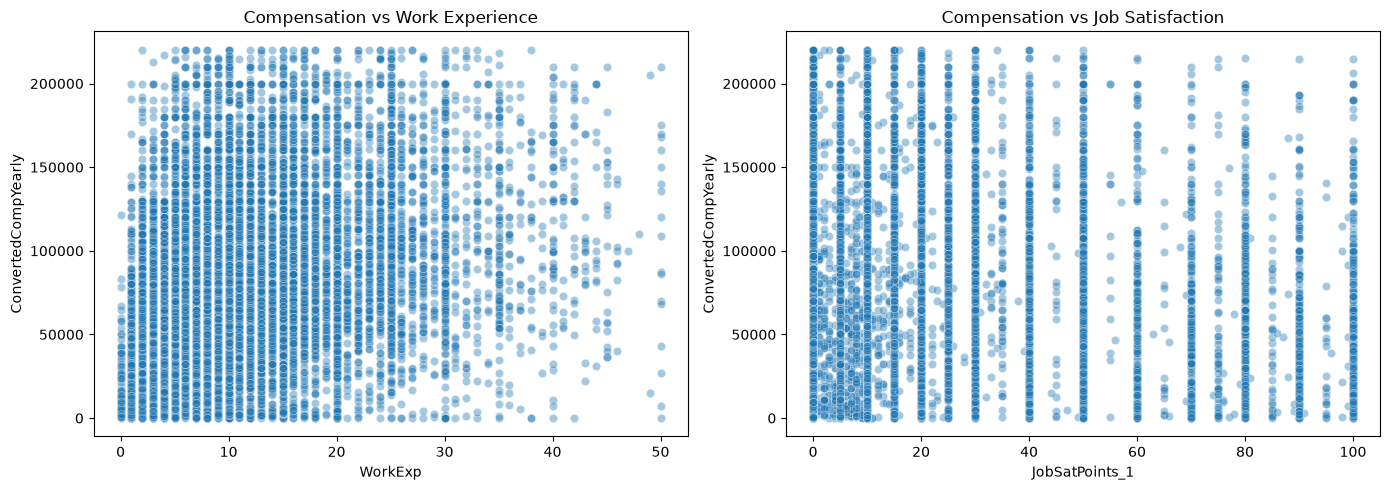

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x='WorkExp', y='ConvertedCompYearly', data=df_no_outliers,
                alpha=0.4, ax=axes[0])
axes[0].set_title('Compensation vs Work Experience')

sns.scatterplot(x='JobSatPoints_1', y='ConvertedCompYearly', data=df_no_outliers,
                alpha=0.4, ax=axes[1])
axes[1].set_title('Compensation vs Job Satisfaction')

plt.tight_layout()
plt.show()